In [1]:
%matplotlib widget
from matplotlib import pyplot as plt

from scipy.optimize import curve_fit
from scipy.signal import find_peaks
from scipy.signal import peak_widths
import numpy as np
import os
import importlib
from sklearn.metrics import mean_squared_error
import copy




os.chdir(r'C:\Users\nberr\ENS_Lyon\Thèse\Code\Permittivity_study')
import Permittivity_study_func
importlib.reload(Permittivity_study_func)
from Permittivity_study_func import *



fontsize=30
import matplotlib as mpl
mpl.rcParams["font.size"] = 18

## Get index data

In [2]:
dir_root = r'H:\commun\Experiments (from 2018)\Nanoscope 2\Projects\ULTRASINGLE\Measurements\AuND_specific_AR_Marguet\Sapphire\AR_estimation\Permittivity_study\all_index_data'
Index_data = get_index_data(dir_root)


## Get experimental data

## Get simulation data

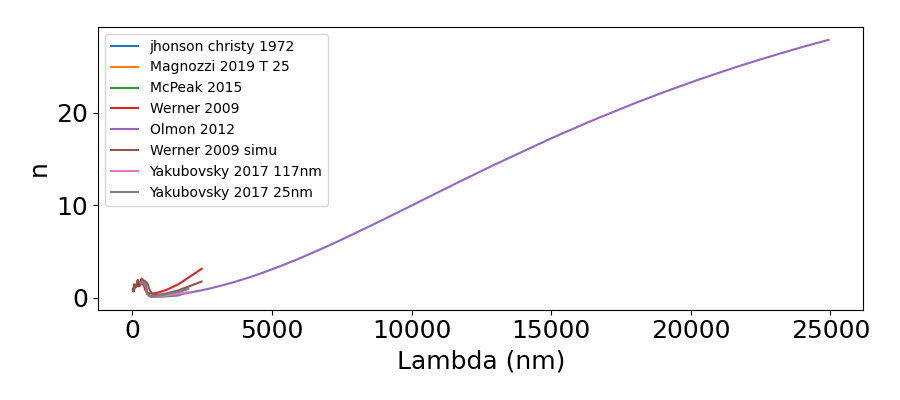

In [3]:
fig, ax = plt.subplots(figsize=(9,4))

for key in Index_data :
    data = Index_data[key]
    ax.plot(data['wl']*1e9, data['n'], label = key)


ax.set_xlabel('Lambda (nm)') 
ax.set_ylabel('n')
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()


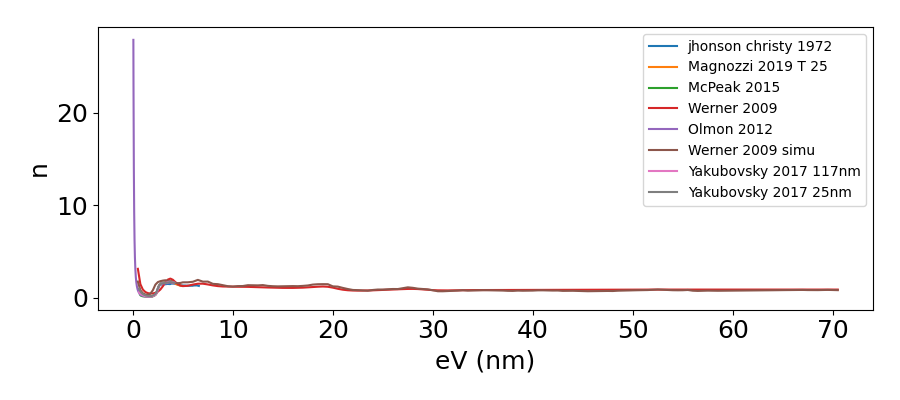

In [4]:
fig, ax = plt.subplots(figsize=(9,4))

for key in Index_data :
    data = Index_data[key]
    ax.plot(1240/(data['wl']*1e9), data['n'], label = key)


ax.set_xlabel('eV (nm)') 
ax.set_ylabel('n')
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()

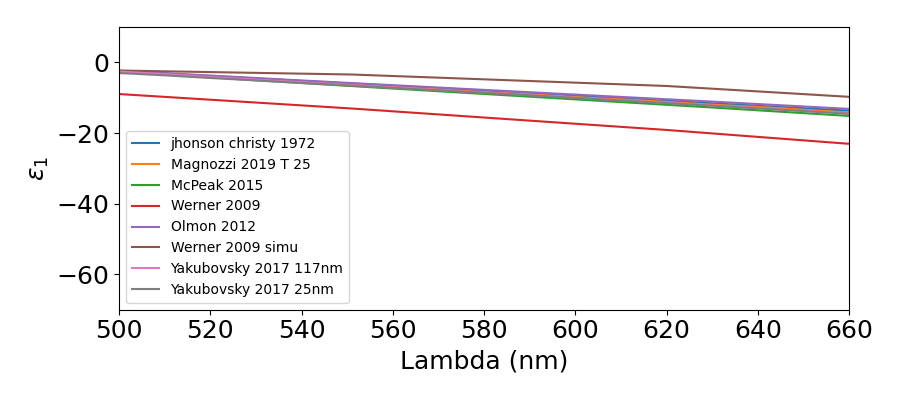

In [5]:
fig, ax = plt.subplots(figsize=(9,4))

for key in Index_data :
    data = Index_data[key]
    ax.plot(data['wl']*1e9, data['eps_1'], label = key)


ax.set_xlim((500, 660))
ax.set_ylim((-70, 10))

ax.set_xlabel('Lambda (nm)') 
ax.set_ylabel(r'$\varepsilon_1$')
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()

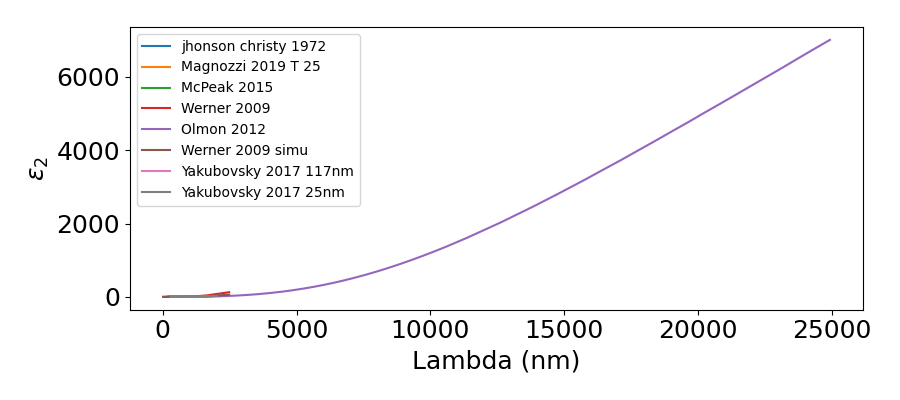

In [6]:
fig, ax = plt.subplots(figsize=(9,4))

for key in Index_data :
    data = Index_data[key]
    ax.plot(data['wl']*1e9, data['eps_2'], label = key)


ax.set_xlabel('Lambda (nm)') 
ax.set_ylabel(r'$\varepsilon_2$')
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()

In [7]:
make_1D_interpolation(Index_data)

In [8]:
key_ref = 'jhonson christy 1972'


WL = np.linspace(500e-9, 700e-9, 50)


compute_LSPR_offset(Index_data, WL, key_ref)


for key in Index_data :
    data = Index_data[key]

    ax.plot(data['LSPR_offset']['WL_ref'], data['LSPR_offset']['WL_equiv'], label=key)



Idée ici :

D'une part, pour chaque lambda = lda_ref, je regarde la valeur de eps1(lda_ref) dans l'article de Jhinson Christy. Ensuite, je regarde pour les autres tables quel lda_equiv permet de vérifier que eps1(lda_equiv) de cette table est égal à eps1(lda_ref). Si on suppose que la position de la résonance est uniquement déterminée par eps1, cela nous donne un lda_equiv qui serait la position de la résonance pour cette table.

Du côté expérimental : je regarde d'un côté pour chaque disque quel est le lda_SPR = lda_equiv mesuré. D'autre part, comme (h, D) est estimé pour le disque, je regarde du côté des simulation quel est le lda(h,D) = lda_ref estimé pour cette morphologie.

Avec ces deux méthodes, je trace le detuning = lda_equiv - lda_ref


NameError: name 'Exp_data' is not defined

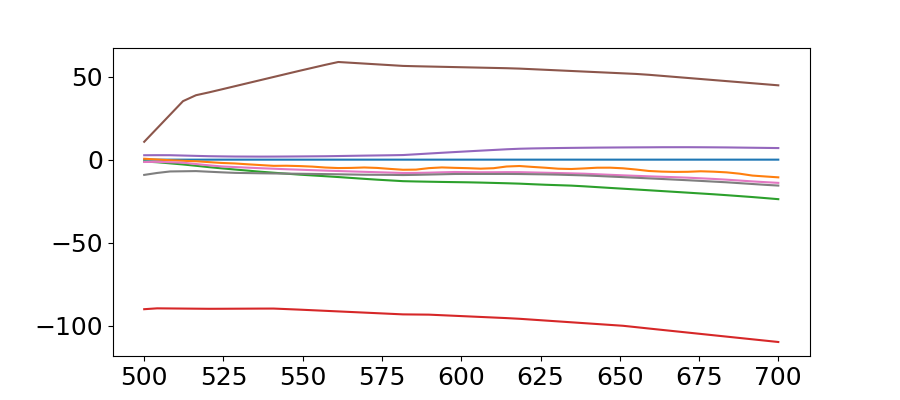

In [9]:
fig, ax = plt.subplots(figsize=(9,4))


for key in Index_data :
    data = Index_data[key]
    ax.plot(data['LSPR_offset']['WL_ref']*1e9, (data['LSPR_offset']['WL_equiv']-data['LSPR_offset']['WL_ref'])*1e9, label = key)


for key in Exp_data :
    spectra = Exp_data[key]
    lda_SPR_meas = spectra['lda_SPR']
    
    lda_SPR_interp = Lda_RBF([[h_1D, spectra['1D_estimation_Aire_SPR']['D']]])[0]

    ax.scatter(lda_SPR_meas, lda_SPR_meas - lda_SPR_interp , color='black' )
    #print(lda_SPR_interp - lda_SPR_meas )


ax.set_xlabel('Lambda (nm)') 
ax.set_ylabel('Detuning (nm)')
ax.set_xlim((500, 660))
ax.set_ylim((-70, 10))
plt.title('h = {} nm'.format(h_1D))
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()